# **Лабораторная работа №2**

## Реализация алгоритма линейной регрессии на Scikit-Learn

### Описание задачи

1. Для выполнения используя  библиотека Scikit-Learn (https://scikit-learn.org)

2. Реализовать метод линейной регрессии для заданного набора данных  используя следующие модели: простая линейная регрессия, линейная регрессия с Ridge регуляризацией, линейная регрессия с LASSO регуляризацией, * линейная регрессия с Elastic Net регуляризацией

3. Отрисовать данные и регрессионные прямые на одном графике (использовать разные цвета с легендой).

4. Выбрать лучшую из полученных моделей используя метрики  MAE, R2, MAPE. Для использования стандартных метрик в Scikit-Learn имеется модуль metrics

5. Метрики для всех моделей собрать в таблицу

6. Сделать вывод по работе и используемым метрикам


In [29]:
import numpy as np
import pandas as pd
from sklearn import linear_model as lm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

### 1. Загрузка данных из файлов

In [5]:
data = pd.read_csv('lab2_1_DS.csv')
data.head()

,age,experience,income
0,25,1,30450
1,30,3,35670
2,47,2,31580
3,32,5,40130
4,43,10,47830


In [6]:
data.describe()

,age,experience,income
count,20.000000,20.000000,20.000000
mean,39.650000,6.200000,40735.500000
std,10.027725,4.124382,8439.797625
min,23.000000,1.000000,27840.000000
25%,31.500000,3.750000,35452.500000
50%,40.000000,5.000000,40190.000000
75%,47.000000,9.000000,45390.000000
max,58.000000,17.000000,63600.000000


In [21]:
X = data[['age', 'experience']].values
y = data['income'].values

### 2. Реализация метода линейной регрессии с использованием указанных моделей

Из-за того, что признаки и целевая переменная слишком разных масштабов, то для моделей с регуляризацией нужно взять достаточно большой коэффициент. Данные различаются порядком $10^3$, поэтому коэффициент должен соответствовать.

In [25]:
models = {
    'Linear Regression': lm.LinearRegression(),
    'Ridge': lm.Ridge(alpha=1.0),
    'Lasso': lm.Lasso(alpha=100.0, max_iter=10000),
    'Elastic Net': lm.ElasticNet(alpha=100.0, l1_ratio=0.5, max_iter=10000)
}

for name, model in models.items():
    model.fit(X, y)
    print(f"{name} coefficients: {model.coef_}, intercept: {model.intercept_}")

Linear Regression coefficients: [ -99.19535546 2162.40419192], intercept: 31261.68985410128
Ridge coefficients: [ -96.40434846 2151.57267751], intercept: 31218.181816062453
Lasso coefficients: [ -94.95997464 2149.88134821], intercept: 31171.3986355945
Elastic Net coefficients: [225.80924537 408.69242049], intercept: 29248.270413901642


### 3. Отрисовка данных и регрессионных прямых

Так как данные имеют 2 признака и 1 целевую переменную, то для отображения регрессионных прямых необходимо обучить каждую модель по отедльности на каждом признаке, чтобы прямые можно было отрисовать на плоскости

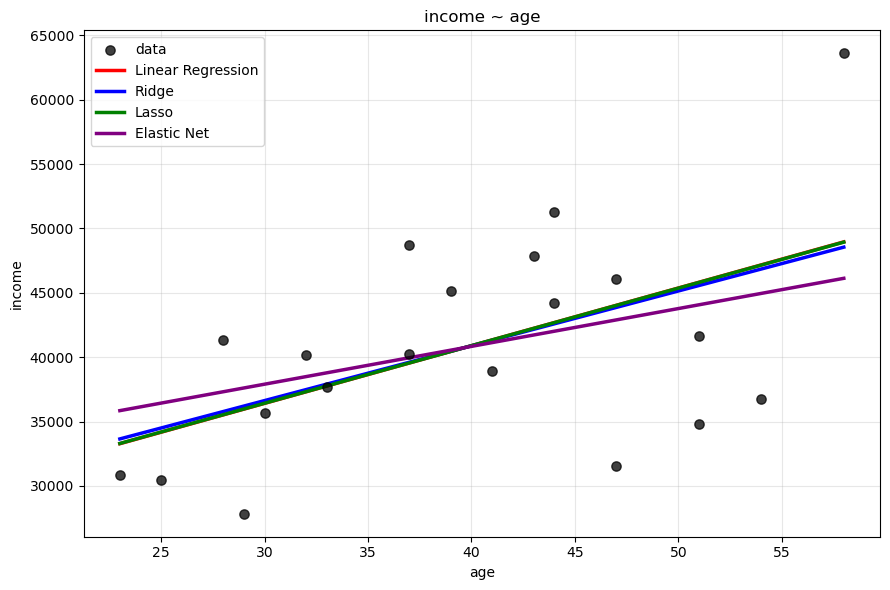

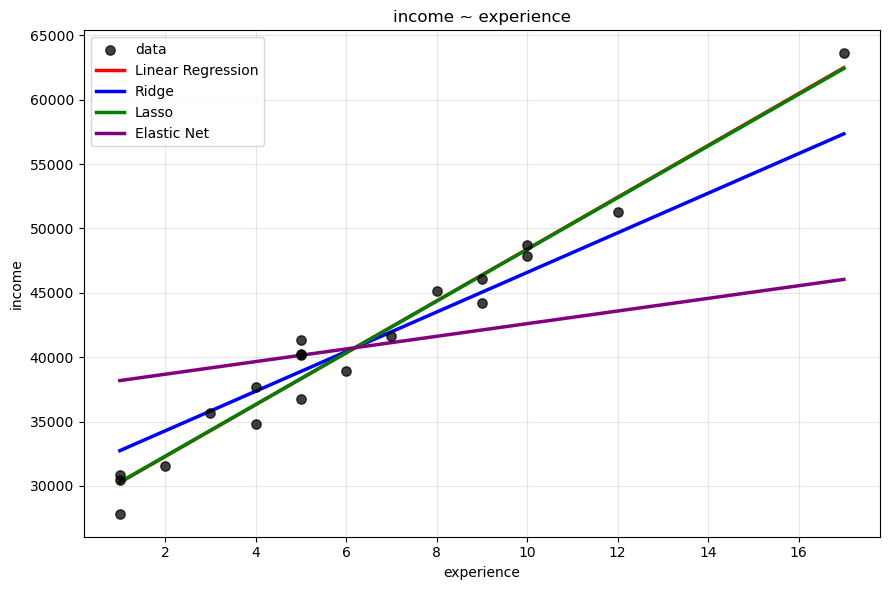

In [26]:
colors = {
    "Linear Regression": "red",
    "Ridge":             "blue",
    "Lasso":             "green",
    "Elastic Net":       "purple",
}

feature_names = ["age", "experience"]

for feat_idx, feat_name in enumerate(feature_names):
    X1d = X[:, [feat_idx]]
    x_line = np.linspace(X1d.min(), X1d.max(), 200).reshape(-1, 1)

    plt.figure(figsize=(9, 6))

    plt.scatter(X1d, y, color="black", alpha=0.75, s=45,
                label="data", zorder=3)

    for name in models:
        m1d = {
            "Linear Regression": lm.LinearRegression(),
            "Ridge":             lm.Ridge(alpha=100.0),
            "Lasso":             lm.Lasso(alpha=100.0, max_iter=10000),
            "Elastic Net":       lm.ElasticNet(alpha=100.0, l1_ratio=0.5, max_iter=10000),
        }[name]
        m1d.fit(X1d, y)
        plt.plot(x_line, m1d.predict(x_line),
                 color=colors[name], linewidth=2.5,
                 label=name, zorder=2)

    plt.xlabel(feat_name)
    plt.ylabel("income")
    plt.title(f"income ~ {feat_name}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

### 4. Оценим метрики MAE, MAPE, R2 на полученных результатах

In [32]:
results = []

for name, model in models.items():
    y_pred = model.predict(X)

    metrics = {
        'Model': name,
        'MAE': mean_absolute_error(y, y_pred),
        'MAPE':mean_absolute_percentage_error(y, y_pred) * 100,
        'R2': r2_score(y, y_pred)
    }

    results.append(metrics)

for r in results:
    print(f'{r["Model"]}: MAE: {r["MAE"]:.2f}, MAPE: {r["MAPE"]:.2f}%, R2: {r["R2"]:.4f}')

Linear Regression: MAE: 981.62, MAPE: 2.50%, R2: 0.9773
Ridge: MAE: 983.05, MAPE: 2.51%, R2: 0.9773
Lasso: MAE: 982.76, MAPE: 2.51%, R2: 0.9773
Elastic Net: MAE: 4697.90, MAPE: 11.84%, R2: 0.5009


In [33]:
result_table = pd.DataFrame(results).set_index('Model').round(3)

print(result_table)

                        MAE    MAPE     R2
Model                                     
Linear Regression   981.620   2.504  0.977
Ridge               983.051   2.509  0.977
Lasso               982.764   2.507  0.977
Elastic Net        4697.900  11.841  0.501


### 5. Вывод

В данной ситуации лучший результат показала модель без регуляризации. Это связано с тем, что набор данных состоит из 20 записей и данные не имеют шума, поэтому регуляризация показывает себя неэффективно в данном случае. Регуляризация также проверялась с $alpha=1$. При таком параметре модели оказываются почти одинаковыми. 